# Phase 2 — Experiments 7 & 8: Learning-Rate Investigation

**Scope:** ONLY these two experiments, per approved plan. No test-set access anywhere in this
notebook (test `.npy` files are never loaded). No Model B/C/D, no new loss, no augmentation,
no class weighting. All Phase 1 files are read-only reference here (Phase 1's own experiment
log is read for comparison, never written to).

**Hypothesis (from Phase 1 baseline training-log analysis):** the baseline's validation loss
oscillated (0.288 -> 0.355 -> 0.310 -> 0.307 -> 0.287 -> 0.298 ...) while train loss/accuracy
were still steadily improving with no plateau when early stopping fired at epoch 17 (best
epoch 12). This pattern — noisy val_loss + still-improving train curve — is consistent with a
learning rate too large for stable late-stage convergence, not a capacity/architecture issue
(already ruled out in Phase 1 via Model B/C).

- **Experiment 7:** `ReduceLROnPlateau` (adaptive, starts at 1e-3, halves on plateau)
- **Experiment 8:** constant lr = 5e-4 (a clean halving of baseline's 1e-3 — chosen over 3e-4
  as the more conventional, less aggressive first diagnostic step, and because it pairs
  naturally with Experiment 7's halving factor for a clean two-experiment comparison)


In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import random, csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

DATA_DIR = Path(".")             # executed with the project root as working directory
P2_MODELS = Path("phase2/models")
P2_FIGURES = Path("phase2/figures")
P2_RESULTS = Path("phase2/results")
P2_LOGS = Path("phase2/logs")
for d in (P2_MODELS, P2_FIGURES, P2_RESULTS, P2_LOGS):
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1787869333.248322  236266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787869333.311422  236266 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787869334.477636  236266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0
GPUs available: []


E0000 00:00:1787869335.333134  236266 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Data — Training and Validation ONLY

The test `.npy` files are never referenced anywhere in this notebook — not loaded, not
imported, not touched. This is a structural guarantee, not just a promise kept by convention.


In [2]:
train_images = np.load(DATA_DIR / "train_images.npy")
train_labels = np.load(DATA_DIR / "train_labels.npy").flatten()
val_images = np.load(DATA_DIR / "val_images.npy")
val_labels = np.load(DATA_DIR / "val_labels.npy").flatten()
# test_images.npy / test_labels.npy are DELIBERATELY NOT loaded in this notebook.

def preprocess_images(images):
    images = images.astype("float32") / 255.0
    return np.expand_dims(images, axis=-1)

X_train, y_train = preprocess_images(train_images), train_labels.astype("int32")
X_val, y_val = preprocess_images(val_images), val_labels.astype("int32")

classes_sorted = sorted(np.unique(y_train))
n_classes = len(classes_sorted)
idx1, idx2 = classes_sorted.index(1), classes_sorted.index(2)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| classes:", n_classes)


X_train: (13932, 64, 64, 1) | X_val: (2452, 64, 64, 1) | classes: 11


## Model A Architecture — Exact Phase 1 Baseline (unchanged)

Identical to `organ_cnn_project.ipynb`'s `build_model_a()` — same layers, filters, kernel
sizes, activations, dropout rate. This function is re-defined here (not imported from the
Phase 1 notebook) to keep Phase 2 fully self-contained, but is byte-for-byte the same
architecture.


In [3]:
def build_model_a(input_shape=(64, 64, 1), n_classes=11):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ], name="model_a_baseline")
    return model

def evaluate_on_val(model):
    probs = model.predict(X_val, verbose=0)
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(y_val, preds)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_val, preds, average="macro", zero_division=0)
    p, r, f1, sup = precision_recall_fscore_support(y_val, preds, average=None, zero_division=0, labels=classes_sorted)
    cm = confusion_matrix(y_val, preds, labels=classes_sorted)
    return dict(probs=probs, preds=preds, acc=acc, macro_p=mp, macro_r=mr, macro_f1=mf1,
                per_p=p, per_r=r, per_f1=f1, sup=sup, cm=cm)

def log_experiment(row):
    fields = ["experiment_id", "hypothesis", "architecture", "total_params", "optimizer",
               "initial_lr", "lr_schedule", "batch_size", "loss", "dropout", "augmentation",
               "seed", "epochs_run", "best_epoch", "best_val_loss",
               "accuracy", "macro_precision", "macro_recall", "macro_f1",
               "class1_f1", "class2_f1", "class1_recall", "class2_recall",
               "train_val_acc_gap_final", "lr_reductions", "result", "conclusion"]
    row = {k: row.get(k, "") for k in fields}
    path = P2_RESULTS / "phase2_experiment_log.csv"
    exists = path.exists()
    with open(path, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        if not exists:
            w.writeheader()
        w.writerow(row)
    print(f"Logged: {row['experiment_id']}")


---
# Experiment 7 — ReduceLROnPlateau

**Hypothesis:** the baseline's noisy validation loss around its plateau reflects a learning
rate too large for stable late-stage convergence; automatically reducing the learning rate
once validation loss stops improving should let the model settle into a better minimum
instead of oscillating past it.

**Single primary change:** add `ReduceLROnPlateau`. Everything else — architecture, batch
size, loss, optimizer type (Adam), initial learning rate, preprocessing, no augmentation, no
class weighting, seed, checkpointing strategy, evaluation methodology — held constant,
identical to Phase 1's Model A baseline.

**Configuration (documented before running):**
- Initial learning rate: 1e-3 (same as baseline)
- Monitor: `val_loss`
- Factor: 0.5 (halve on plateau)
- Patience: 2 (shorter than `EarlyStopping`'s patience of 5, so at least one LR reduction can
  occur before early stopping would otherwise fire)
- Minimum learning rate: 1e-5
- `EarlyStopping`: unchanged from baseline (`monitor=val_loss`, patience=5, `restore_best_weights=True`)
- Max epochs: 30 (unchanged from baseline)

**Success criterion:** Macro F1 meaningfully exceeds 0.8053 (outside the ~0.01-0.02 documented
run-to-run margin), without a widening train/val gap.
**Failure criterion:** Macro F1 does not improve, or improves only within noise, or comes with
a clearly worse train/val gap.


In [4]:
keras.utils.set_random_seed(SEED)
model_e7 = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_e7.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

lr_history = []
class LRTracker(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        lr_history.append(float(self.model.optimizer.learning_rate.numpy()))

callbacks_e7 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(P2_MODELS / "modelA_reduce_lr_on_plateau.keras"),
                                     monitor="val_loss", save_best_only=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    LRTracker(),
]

history_e7 = model_e7.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=64,
    callbacks=callbacks_e7, verbose=2,
)

print("\nLearning-rate history (per epoch):", lr_history)
n_reductions = sum(1 for i in range(1, len(lr_history)) if lr_history[i] < lr_history[i-1])
print(f"Number of LR reductions: {n_reductions}")


Epoch 1/30


W0000 00:00:1787869336.017858  236266 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.
W0000 00:00:1787869336.165028  236266 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.
E0000 00:00:1787869336.256180  236266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


W0000 00:00:1787869345.263937  236266 cpu_allocator_impl.cc:82] Allocation of 40173568 exceeds 10% of free system memory.
W0000 00:00:1787869345.290404  236266 cpu_allocator_impl.cc:82] Allocation of 40173568 exceeds 10% of free system memory.
E0000 00:00:1787869345.310339  236266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 0.81539, saving model to phase2/models/modelA_reduce_lr_on_plateau.keras



Epoch 1: finished saving model to phase2/models/modelA_reduce_lr_on_plateau.keras


218/218 - 10s - 45ms/step - accuracy: 0.4376 - loss: 1.5824 - val_accuracy: 0.7174 - val_loss: 0.8154 - learning_rate: 0.0010


... (50 outputs left out)

218/218 - 13s - 58ms/step - accuracy: 0.8575 - loss: 0.3193 - val_accuracy: 0.8891 - val_loss: 0.3005 - learning_rate: 2.5000e-04


Epoch 15: early stopping


Restoring model weights from the end of the best epoch: 10.



Learning-rate history (per epoch): [0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0005000000237487257, 0.0005000000237487257, 0.0002500000118743628, 0.0002500000118743628]
Number of LR reductions: 2


In [5]:
res_e7 = evaluate_on_val(model_e7)
print(f"Validation Accuracy:        {res_e7['acc']:.4f}")
print(f"Validation Macro Precision: {res_e7['macro_p']:.4f}")
print(f"Validation Macro Recall:    {res_e7['macro_r']:.4f}")
print(f"Validation Macro F1:        {res_e7['macro_f1']:.4f}   <-- primary metric")
print()
print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, res_e7["per_p"], res_e7["per_r"], res_e7["per_f1"], res_e7["sup"]):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


W0000 00:00:1787869516.821122  236266 cpu_allocator_impl.cc:82] Allocation of 40173568 exceeds 10% of free system memory.
E0000 00:00:1787869516.885202  236266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8903
Validation Macro Precision: 0.8326
Validation Macro Recall:    0.8338
Validation Macro F1:        0.8156   <-- primary metric

 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.955 |    0.894 |    0.923 |      188
     1 |      0.516 |    0.913 |    0.660 |      104
     2 |      0.438 |    0.074 |    0.126 |       95
     3 |      0.996 |    0.980 |    0.988 |      246
     4 |      0.750 |    0.879 |    0.809 |      140
     5 |      0.822 |    0.786 |    0.804 |      159
     6 |      0.953 |    0.994 |    0.973 |      491
     7 |      0.940 |    0.893 |    0.916 |      261
     8 |      0.899 |    0.909 |    0.904 |      275
     9 |      0.932 |    0.879 |    0.904 |      280
    10 |      0.958 |    0.972 |    0.965 |      213


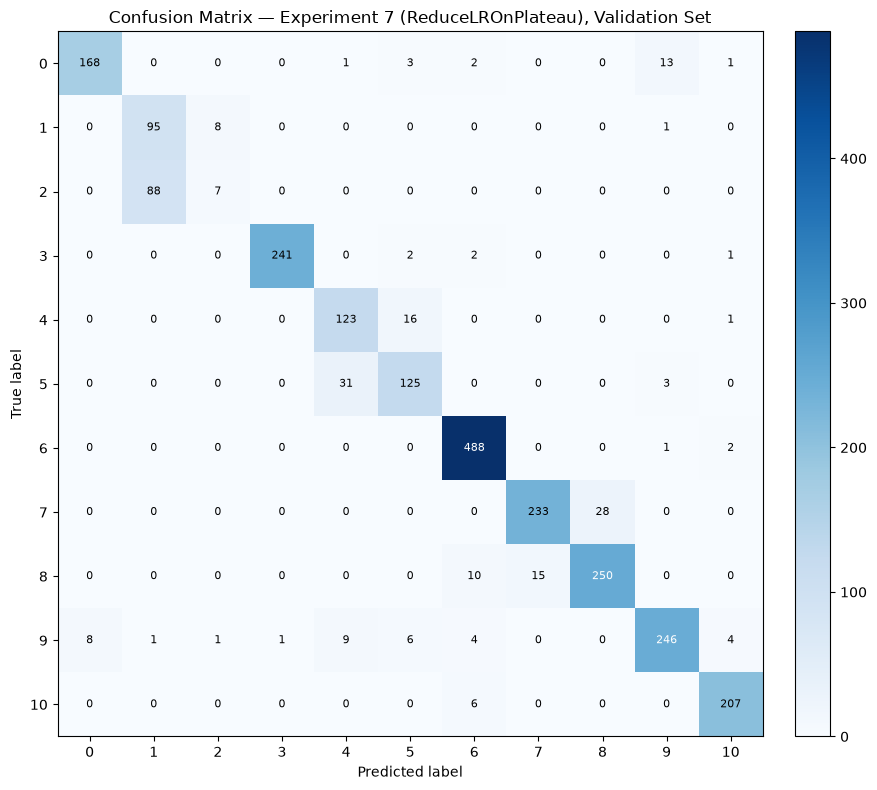

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(res_e7["cm"], cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Experiment 7 (ReduceLROnPlateau), Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        v = res_e7["cm"][i, j]
        ax.text(j, i, str(v), ha="center", va="center",
                 color="white" if v > res_e7["cm"].max()/2 else "black", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(P2_FIGURES / "exp7_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


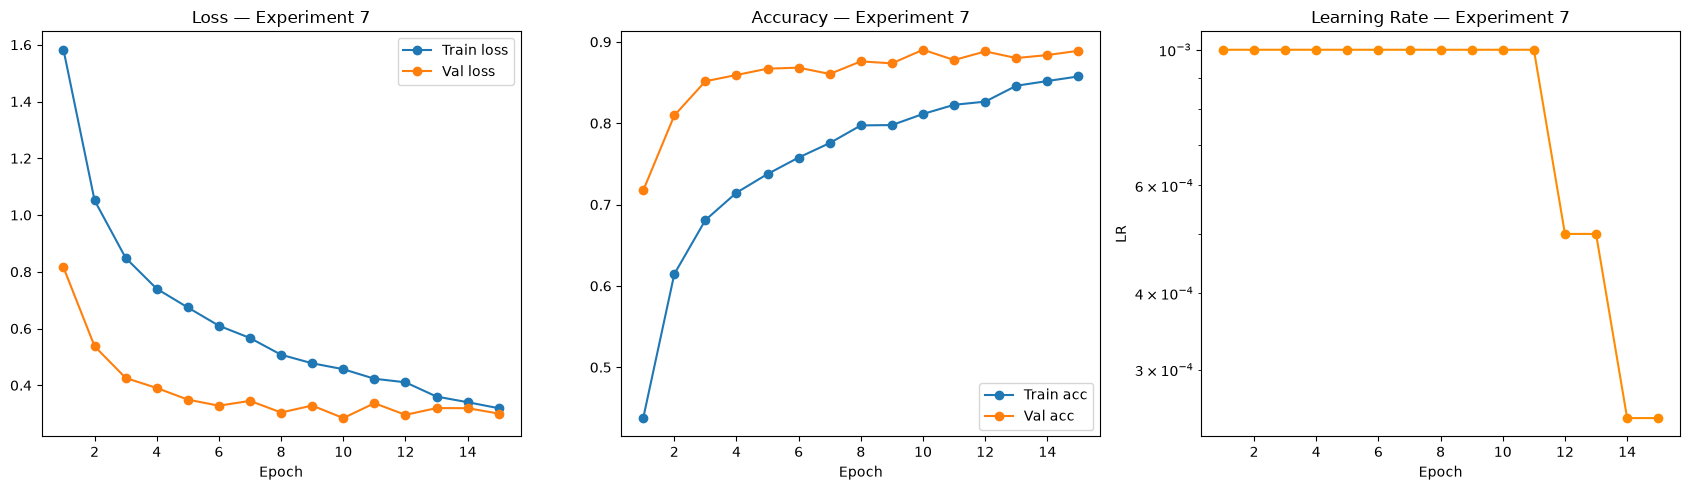

Experiment 7 trained for 15 epochs; best val_loss 0.2846 at epoch 10
Final train/val accuracy gap: -0.0315


In [7]:
hist7 = history_e7.history
epochs7 = range(1, len(hist7["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(epochs7, hist7["loss"], label="Train loss", marker="o")
axes[0].plot(epochs7, hist7["val_loss"], label="Val loss", marker="o")
axes[0].set_title("Loss — Experiment 7"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs7, hist7["accuracy"], label="Train acc", marker="o")
axes[1].plot(epochs7, hist7["val_accuracy"], label="Val acc", marker="o")
axes[1].set_title("Accuracy — Experiment 7"); axes[1].set_xlabel("Epoch"); axes[1].legend()

axes[2].plot(epochs7, lr_history, marker="o", color="darkorange")
axes[2].set_title("Learning Rate — Experiment 7"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("LR")
axes[2].set_yscale("log")

plt.tight_layout()
plt.savefig(P2_FIGURES / "exp7_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

best_epoch_e7 = int(np.argmin(hist7["val_loss"])) + 1
print(f"Experiment 7 trained for {len(epochs7)} epochs; best val_loss {min(hist7['val_loss']):.4f} at epoch {best_epoch_e7}")
final_gap_e7 = hist7["accuracy"][-1] - hist7["val_accuracy"][-1]
print(f"Final train/val accuracy gap: {final_gap_e7:+.4f}")


In [8]:
log_experiment({
    "experiment_id": "Exp7: Model A + ReduceLROnPlateau",
    "hypothesis": "Noisy val_loss plateau in baseline indicates LR too high for late-stage convergence; adaptive reduction should stabilize and improve Macro F1",
    "architecture": "Model A (unchanged, 286,219 params)",
    "total_params": model_e7.count_params(),
    "optimizer": "Adam",
    "initial_lr": 1e-3,
    "lr_schedule": f"ReduceLROnPlateau(monitor=val_loss, factor=0.5, patience=2, min_lr=1e-5); {n_reductions} reduction(s) occurred",
    "batch_size": 64,
    "loss": "sparse_categorical_crossentropy",
    "dropout": 0.5,
    "augmentation": "none",
    "seed": SEED,
    "epochs_run": len(epochs7),
    "best_epoch": best_epoch_e7,
    "best_val_loss": round(min(hist7["val_loss"]), 4),
    "accuracy": round(res_e7["acc"], 4),
    "macro_precision": round(res_e7["macro_p"], 4),
    "macro_recall": round(res_e7["macro_r"], 4),
    "macro_f1": round(res_e7["macro_f1"], 4),
    "class1_f1": round(res_e7["per_f1"][idx1], 4),
    "class2_f1": round(res_e7["per_f1"][idx2], 4),
    "class1_recall": round(res_e7["per_r"][idx1], 4),
    "class2_recall": round(res_e7["per_r"][idx2], 4),
    "train_val_acc_gap_final": round(final_gap_e7, 4),
    "lr_reductions": n_reductions,
    "result": "TBD -- see comparison section",
    "conclusion": "TBD -- see comparison section",
})


Logged: Exp7: Model A + ReduceLROnPlateau


---
# Experiment 8 — Lower Constant Learning Rate (5e-4)

**Hypothesis:** if 1e-3 is simply too large a fixed step size for stable late-stage
convergence, a smaller *constant* learning rate should converge more smoothly and potentially
reach a better minimum, without needing an adaptive schedule.

**Why 5e-4 over 3e-4:** 5e-4 is a clean halving of the baseline's 1e-3 — the standard,
conventional first diagnostic step (less aggressive than a 3.3x reduction to 3e-4), and it
pairs directly with Experiment 7's halving factor (0.5) for a clean, comparable pair of
experiments: "adaptive halving over time" (Exp 7) vs. "halve once and hold constant" (Exp 8).
A 3e-4 run risks needing more than the 30-epoch budget / 5-epoch patience to fully converge,
which would confound "did the LR help" with "did it just not have enough epochs."

**Single primary change:** constant learning rate = 5e-4 instead of 1e-3. Everything else
identical to the Phase 1 baseline (same as Experiment 7's constant list).

**Success / failure criteria:** identical to Experiment 7.


In [9]:
keras.utils.set_random_seed(SEED)
model_e8 = build_model_a(input_shape=X_train.shape[1:], n_classes=n_classes)
model_e8.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_e8 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(str(P2_MODELS / "modelA_lr_5e-4.keras"),
                                     monitor="val_loss", save_best_only=True, verbose=1),
]

history_e8 = model_e8.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=64,
    callbacks=callbacks_e8, verbose=2,
)


Epoch 1/30


E0000 00:00:1787869532.647195  236266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}



Epoch 1: val_loss improved from None to 1.06044, saving model to phase2/models/modelA_lr_5e-4.keras



Epoch 1: finished saving model to phase2/models/modelA_lr_5e-4.keras


218/218 - 14s - 64ms/step - accuracy: 0.3720 - loss: 1.7550 - val_accuracy: 0.5722 - val_loss: 1.0604


Epoch 2/30


... (69 outputs left out)


Epoch 22: val_loss did not improve from 0.32533


218/218 - 12s - 57ms/step - accuracy: 0.8458 - loss: 0.3601 - val_accuracy: 0.8752 - val_loss: 0.3502


Epoch 22: early stopping


Restoring model weights from the end of the best epoch: 17.


In [10]:
res_e8 = evaluate_on_val(model_e8)
print(f"Validation Accuracy:        {res_e8['acc']:.4f}")
print(f"Validation Macro Precision: {res_e8['macro_p']:.4f}")
print(f"Validation Macro Recall:    {res_e8['macro_r']:.4f}")
print(f"Validation Macro F1:        {res_e8['macro_f1']:.4f}   <-- primary metric")
print()
print(f"{'Class':>6} | {'Precision':>10} | {'Recall':>8} | {'F1':>8} | {'Support':>8}")
for c, p, r, f, s in zip(classes_sorted, res_e8["per_p"], res_e8["per_r"], res_e8["per_f1"], res_e8["sup"]):
    print(f"{c:>6} | {p:>10.3f} | {r:>8.3f} | {f:>8.3f} | {s:>8d}")


E0000 00:00:1787869795.010154  236266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Validation Accuracy:        0.8805
Validation Macro Precision: 0.8229
Validation Macro Recall:    0.8222
Validation Macro F1:        0.8008   <-- primary metric

 Class |  Precision |   Recall |       F1 |  Support
     0 |      0.941 |    0.851 |    0.894 |      188
     1 |      0.518 |    0.952 |    0.671 |      104
     2 |      0.429 |    0.032 |    0.059 |       95
     3 |      0.988 |    0.980 |    0.984 |      246
     4 |      0.781 |    0.814 |    0.797 |      140
     5 |      0.815 |    0.805 |    0.810 |      159
     6 |      0.947 |    0.990 |    0.968 |      491
     7 |      0.897 |    0.870 |    0.883 |      261
     8 |      0.876 |    0.876 |    0.876 |      275
     9 |      0.914 |    0.907 |    0.910 |      280
    10 |      0.945 |    0.967 |    0.956 |      213


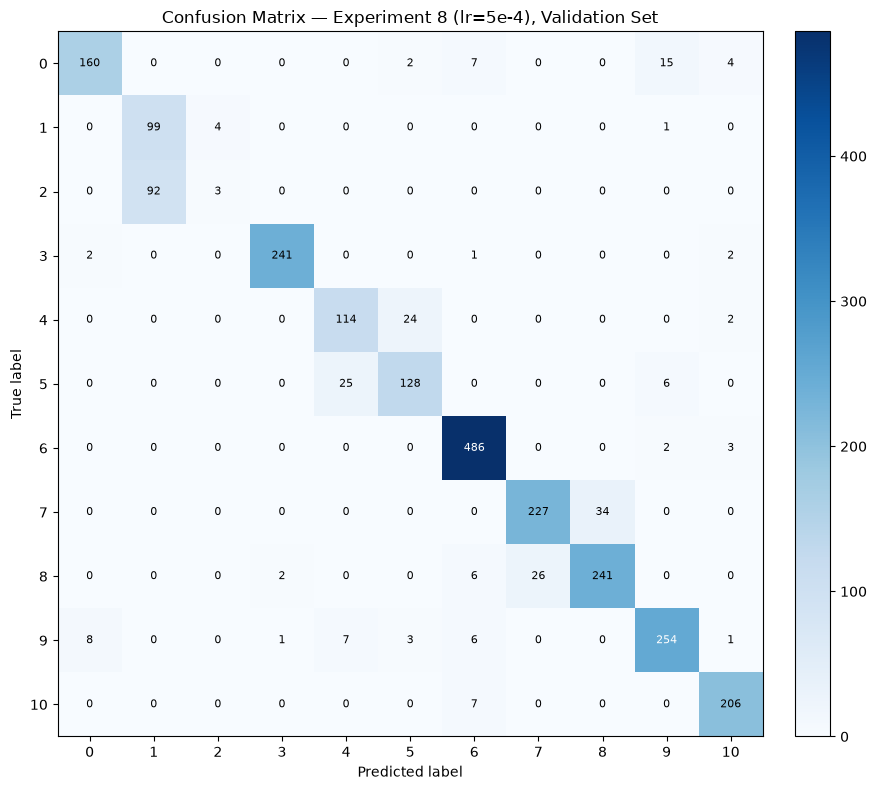

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(res_e8["cm"], cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Experiment 8 (lr=5e-4), Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        v = res_e8["cm"][i, j]
        ax.text(j, i, str(v), ha="center", va="center",
                 color="white" if v > res_e8["cm"].max()/2 else "black", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(P2_FIGURES / "exp8_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


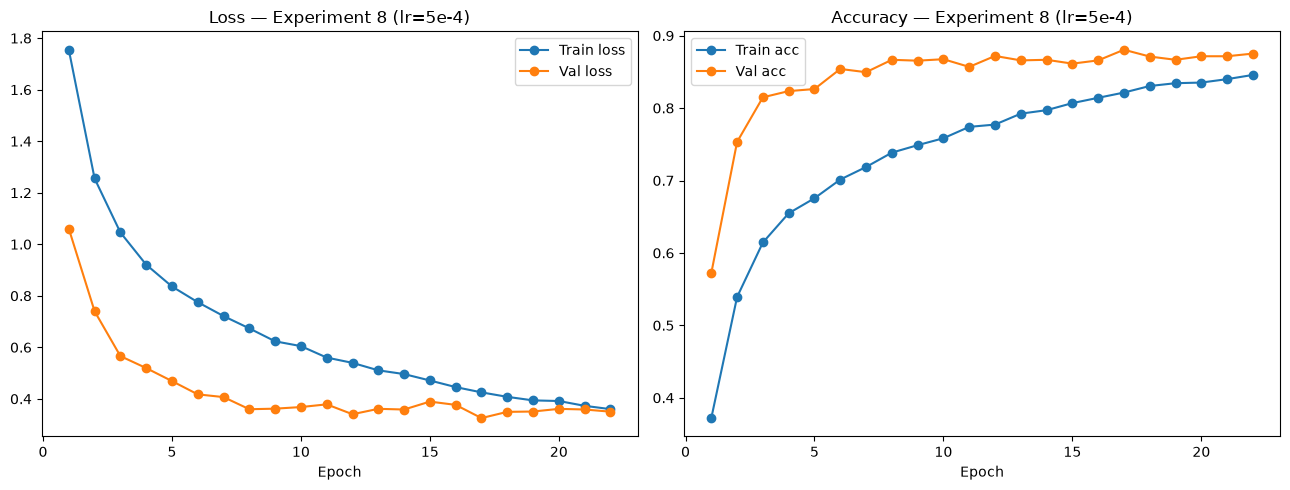

Experiment 8 trained for 22 epochs; best val_loss 0.3253 at epoch 17
Final train/val accuracy gap: -0.0295


In [12]:
hist8 = history_e8.history
epochs8 = range(1, len(hist8["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs8, hist8["loss"], label="Train loss", marker="o")
axes[0].plot(epochs8, hist8["val_loss"], label="Val loss", marker="o")
axes[0].set_title("Loss — Experiment 8 (lr=5e-4)"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs8, hist8["accuracy"], label="Train acc", marker="o")
axes[1].plot(epochs8, hist8["val_accuracy"], label="Val acc", marker="o")
axes[1].set_title("Accuracy — Experiment 8 (lr=5e-4)"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.savefig(P2_FIGURES / "exp8_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

best_epoch_e8 = int(np.argmin(hist8["val_loss"])) + 1
print(f"Experiment 8 trained for {len(epochs8)} epochs; best val_loss {min(hist8['val_loss']):.4f} at epoch {best_epoch_e8}")
final_gap_e8 = hist8["accuracy"][-1] - hist8["val_accuracy"][-1]
print(f"Final train/val accuracy gap: {final_gap_e8:+.4f}")


In [13]:
log_experiment({
    "experiment_id": "Exp8: Model A + constant lr=5e-4",
    "hypothesis": "Baseline lr=1e-3 may be too large for stable late-stage convergence; a smaller constant lr should converge more smoothly to a better minimum",
    "architecture": "Model A (unchanged, 286,219 params)",
    "total_params": model_e8.count_params(),
    "optimizer": "Adam",
    "initial_lr": 5e-4,
    "lr_schedule": "none (constant)",
    "batch_size": 64,
    "loss": "sparse_categorical_crossentropy",
    "dropout": 0.5,
    "augmentation": "none",
    "seed": SEED,
    "epochs_run": len(epochs8),
    "best_epoch": best_epoch_e8,
    "best_val_loss": round(min(hist8["val_loss"]), 4),
    "accuracy": round(res_e8["acc"], 4),
    "macro_precision": round(res_e8["macro_p"], 4),
    "macro_recall": round(res_e8["macro_r"], 4),
    "macro_f1": round(res_e8["macro_f1"], 4),
    "class1_f1": round(res_e8["per_f1"][idx1], 4),
    "class2_f1": round(res_e8["per_f1"][idx2], 4),
    "class1_recall": round(res_e8["per_r"][idx1], 4),
    "class2_recall": round(res_e8["per_r"][idx2], 4),
    "train_val_acc_gap_final": round(final_gap_e8, 4),
    "lr_reductions": 0,
    "result": "TBD -- see comparison section",
    "conclusion": "TBD -- see comparison section",
})


Logged: Exp8: Model A + constant lr=5e-4


---
# Comparison with Phase 1 Baseline

Phase 1's baseline numbers are read directly from `results/metrics/experiment_log.csv`
(read-only — this notebook never writes to that file).


In [14]:
import csv as _csv
with open("results/metrics/experiment_log.csv") as f:
    phase1_rows = list(_csv.DictReader(f))
baseline_row = [r for r in phase1_rows if r["experiment"] == "Exp1: Baseline Model A"][0]

baseline = {
    "accuracy": float(baseline_row["accuracy"]),
    "macro_precision": float(baseline_row["macro_precision"]),
    "macro_recall": float(baseline_row["macro_recall"]),
    "macro_f1": float(baseline_row["macro_f1"]),
    "class1_f1": float(baseline_row["class1_f1"]),
    "class2_f1": float(baseline_row["class2_f1"]),
}

print(f"{'Metric':>18} | {'Phase1 Baseline':>16} | {'Exp7 ReduceLR':>14} | {'Exp8 lr=5e-4':>13}")
for name, key in [("Accuracy","accuracy"), ("Macro Precision","macro_precision"),
                    ("Macro Recall","macro_recall"), ("Macro F1","macro_f1"),
                    ("Class 1 F1","class1_f1"), ("Class 2 F1","class2_f1")]:
    b = baseline[key]
    e7 = res_e7["macro_f1"] if key=="macro_f1" else (res_e7["acc"] if key=="accuracy" else
          (res_e7["macro_p"] if key=="macro_precision" else (res_e7["macro_r"] if key=="macro_recall" else
          (res_e7["per_f1"][idx1] if key=="class1_f1" else res_e7["per_f1"][idx2]))))
    e8 = res_e8["macro_f1"] if key=="macro_f1" else (res_e8["acc"] if key=="accuracy" else
          (res_e8["macro_p"] if key=="macro_precision" else (res_e8["macro_r"] if key=="macro_recall" else
          (res_e8["per_f1"][idx1] if key=="class1_f1" else res_e8["per_f1"][idx2]))))
    print(f"{name:>18} | {b:>16.4f} | {e7:>14.4f} | {e8:>13.4f}")

print()
REPRO_MARGIN = 0.02
delta7 = res_e7["macro_f1"] - baseline["macro_f1"]
delta8 = res_e8["macro_f1"] - baseline["macro_f1"]
print(f"Exp7 Macro F1 delta vs baseline: {delta7:+.4f}  ({'within' if abs(delta7)<=REPRO_MARGIN else 'OUTSIDE'} documented ~0.01-0.02 noise margin)")
print(f"Exp8 Macro F1 delta vs baseline: {delta8:+.4f}  ({'within' if abs(delta8)<=REPRO_MARGIN else 'OUTSIDE'} documented ~0.01-0.02 noise margin)")


            Metric |  Phase1 Baseline |  Exp7 ReduceLR |  Exp8 lr=5e-4
          Accuracy |           0.8907 |         0.8903 |        0.8805
   Macro Precision |           0.8866 |         0.8326 |        0.8229
      Macro Recall |           0.8353 |         0.8338 |        0.8222
          Macro F1 |           0.8053 |         0.8156 |        0.8008
        Class 1 F1 |           0.6844 |         0.6597 |        0.6712
        Class 2 F1 |           0.0208 |         0.1261 |        0.0588

Exp7 Macro F1 delta vs baseline: +0.0103  (within documented ~0.01-0.02 noise margin)
Exp8 Macro F1 delta vs baseline: -0.0045  (within documented ~0.01-0.02 noise margin)


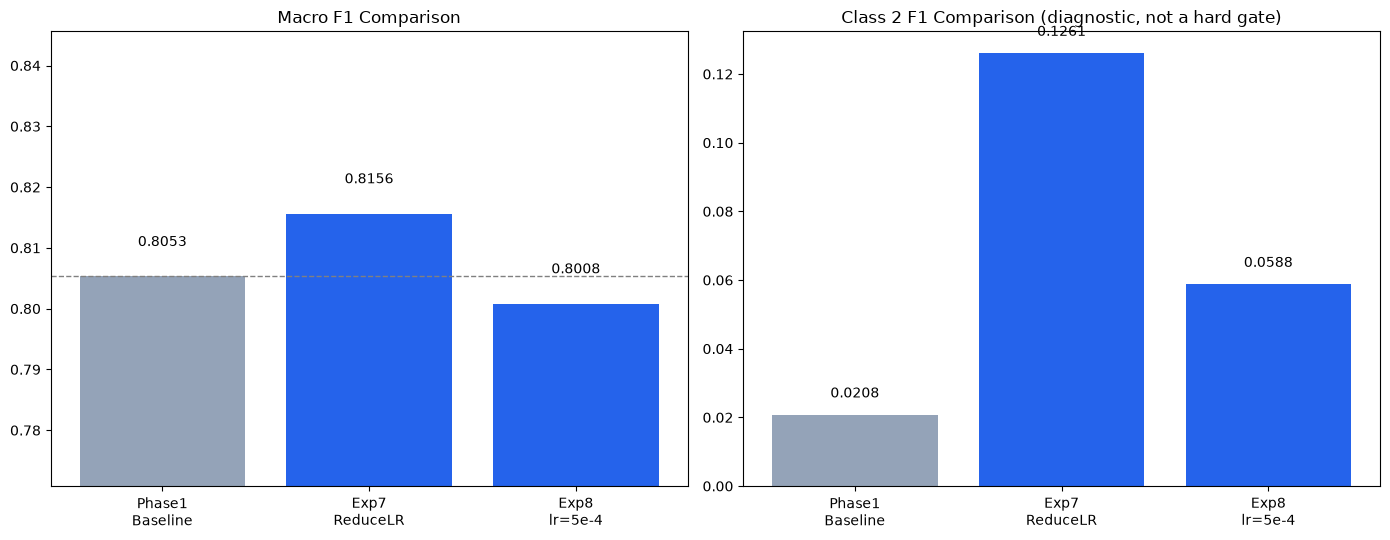

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
labels = ["Phase1\nBaseline", "Exp7\nReduceLR", "Exp8\nlr=5e-4"]
macro_f1_vals = [baseline["macro_f1"], res_e7["macro_f1"], res_e8["macro_f1"]]
colors = ["#94A3B8", "#2563EB", "#2563EB"]
bars = axes[0].bar(labels, macro_f1_vals, color=colors)
for b, v in zip(bars, macro_f1_vals):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontsize=10)
axes[0].set_ylim(min(macro_f1_vals)-0.03, max(macro_f1_vals)+0.03)
axes[0].set_title("Macro F1 Comparison")
axes[0].axhline(baseline["macro_f1"], color="gray", linestyle="--", linewidth=1)

class2_vals = [baseline["class2_f1"], res_e7["per_f1"][idx2], res_e8["per_f1"][idx2]]
bars2 = axes[1].bar(labels, class2_vals, color=colors)
for b, v in zip(bars2, class2_vals):
    axes[1].text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.4f}", ha="center", fontsize=10)
axes[1].set_title("Class 2 F1 Comparison (diagnostic, not a hard gate)")

plt.tight_layout()
plt.savefig(P2_FIGURES / "phase2_vs_phase1_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


---
## Stop Point

Per the approved plan, this notebook stops here. No Model D, no AdamW, no new loss, no
augmentation, no class weighting, no additional hyperparameter tuning, and **no test-set
evaluation** were performed. Results and recommendation are reported back to the project
owner outside this notebook, in the chat response.
